# 11 · How the method was improved, step by step

The deployed land-use forecast was improved in steps. The ideas came from four places:

| Source | What it gave |
|---|---|
| **Reproducing the published score** (notebooks 05–06) | Corrections to how the forecast is scored and to its inputs |
| **The intern's review** (the *improvement approach*, notebooks 01–04, 06–07) | Land-cover history features, seasonal vegetation features, averaging several models |
| **The land-change literature** (notebook 08) | Contagion: new change happens near recent change (Rosa et al. 2013) |
| **The tool comparison** (notebooks 00, 08–09) | Logistic regression, the model of MOLUSCE and CLUE-S; FLUS's neural network |

Every idea was judged by the same rule, fixed before the tests:

* **Chosen on 2023→2024, tested once on 2024→2025.** An idea is adopted only if it gains on both,
  each time by more than the spread across random seeds (Bouthillier et al. 2021).
* **It beats random placement** of the same amount of change (Pontius et al. 2004).
* **It passes the flip-back check:** it does not find less genuinely new change (change into a class
  the pixel has not held since 2017) than the method it improves. On Esri's annual maps most change
  is pixels flipping back between trees and rangeland, which a forecast can score on without
  forecasting land change (notebook 06).

**Score: the Figure of Merit** (Pontius et al. 2008): correctly forecast changes ÷ (observed ∪
forecast changes), given the observed amount of each transition, on Guinea at 250 m. This notebook
only reads the results saved by notebooks 05–09; the details are there.

In [1]:
import sys; sys.path.insert(0, "../scripts")              # shared code: landuse_experiments/scripts/
import nb_helpers as H
import numpy as np, pandas as pd, matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "figure.facecolor": H.SURFACE})
read = lambda name: pd.read_csv(H.SUMMARY / f"{name}.csv").set_index("Configuration")
v, t = "FoM % 2023→2024", "FoM % 2024→2025"
cv, ct = "Check: new-change FoM % 2023→2024", "Check: new-change FoM % 2024→2025"
r07, r08, r09 = read("07_results"), read("08_models"), read("09_models")
published = pd.read_csv(H.SUMMARY / "05_baseline.csv").set_index("Mode").loc["Expander-only"]

## 1 · From the published score to a fair starting point

In [2]:
start = pd.DataFrame([
    {"Step": "Published score", "Notebook": "05", t: published["Published (whole box) FoM %"],
     "What changed": "As in the methodology document (§7.1)"},
    {"Step": "Scored on Guinea only", "Notebook": "05", t: published["Guinea FoM %"],
     "What changed": "The published score covered Guinea's bounding box, 43% of it in neighbouring countries"},
    {"Step": "Corrected inputs (mean of 3 seeds)", "Notebook": "06", v: r08.loc["Deployed method (mean of 3 seeds)", v],
     t: r08.loc["Deployed method (mean of 3 seeds)", t],
     "What changed": "Predictor names, predictor dates (after the forecast start) and training area (blank predictors outside Guinea) fixed"}])
H.show(start[["Step", "Notebook", v, t, "What changed"]])

Step,Notebook,FoM % 2023→2024,FoM % 2024→2025,What changed
Published score,05,,13.80,As in the methodology document (§7.1)
Scored on Guinea only,05,,17.32,"The published score covered Guinea's bounding box, 43% of it in neighbouring countries"
Corrected inputs (mean of 3 seeds),06,15.58,19.07,"Predictor names, predictor dates (after the forecast start) and training area (blank predictors outside Guinea) fixed"


**Reading:**

* **The published 13.80% becomes 17.32% when the same forecast is scored on Guinea only**, and
  **19.07% with the three input problems fixed**. Its hold-out year is also 2024→2025, not
  2023→2024 as labelled (notebook 05).
* **19.07% is the starting point of every step below**, 2.2 times random placement (8.71%).

## 2 · Every idea, in order

In [3]:
def step(n, idea, source, nb, table, row, decision):
    return {"Step": n, "Idea": idea, "Source": source, "Notebook": nb,
            **table.loc[row, [v, t, ct]].to_dict(), "Decision": decision}


steps = pd.DataFrame([
    step(0, "Deployed method, corrected inputs (mean of 3 seeds)", "Reproducing the published score", "06", r08,
         "Deployed method (mean of 3 seeds)", "starting point"),
    step(1, "+ land-cover history features", "Intern's review", "06–07", r07,
         "Deployed method + history features", "not adopted: predicts flicker"),
    step(2, "History models, averaged", "Intern's review", "06–07", r07,
         "History models, averaged", "not adopted: predicts flicker"),
    step(3, "Hybrid: returns and new change modelled apart", "Ours, after the intern's review", "07", r07,
         "Hybrid (split from the previous interval)", "not adopted: predicts flicker"),
    step(4, "+ seasonal MODIS vegetation features", "Intern's review", "07", r07,
         "Deployed method + seasonal", "not adopted: no gain on the test year"),
    step(5, "+ contagion features (mean of 3 seeds)", "Literature (Rosa et al. 2013)", "08", r08,
         "Deployed + contagion (mean of 3 seeds)", "adopted"),
    step(6, "Logistic regression", "Tool comparison: MOLUSCE, CLUE-S", "08", r08,
         "Logistic regression", "adopted, in step 7"),
    step(7, "Contagion model and logistic regression, averaged (mean of 3 seeds)", "Intern's review (averaging) + MOLUSCE",
         "08", r08, "Deployed + contagion and logistic regression, averaged (mean of 3 seeds)",
         "adopted: the improved method of the tool comparison"),
    step(8, "+ first copy of FLUS's network (mean of 3 seeds)", "Tool comparison: FLUS", "09", r09,
         "Improved method + occurrence network (mean of 3 seeds)", "not adopted: no gain on the test year"),
    step(9, "+ neural network per transition (mean of 3 seeds)", "Tool comparison: FLUS", "09", r09,
         "Improved method + network per transition (mean of 3 seeds)", "not adopted: no gain"),
    step(10, "+ FLUS's own maps (3 runs)", "Tool comparison: FLUS", "09", r09,
         "Improved method + FLUS's own maps (mean of 3)", "passes, but needs FLUS's program each year"),
    step(11, "+ FLUS's network reproduced in code (mean of 3 seeds)", "FLUS manual and files", "09", r09,
         "Improved method + copy of FLUS's network (mean of 3)", "adopted: the improved method now"),
])
floor = r08.loc["Random placement (mean of 3 draws)", t]
steps["× random 2024→2025"] = steps[t] / floor
steps.to_csv(H.SUMMARY / "11_steps.csv", index=False)
print(f"Random placement of the same amount of change: {floor:.2f}% on 2024→2025")
H.show(steps.rename(columns={ct: "Flip-back check: new-change FoM % 2024→2025"}))

Random placement of the same amount of change: 8.71% on 2024→2025


Step,Idea,Source,Notebook,FoM % 2023→2024,FoM % 2024→2025,Flip-back check: new-change FoM % 2024→2025,Decision,× random 2024→2025
0,"Deployed method, corrected inputs (mean of 3 seeds)",Reproducing the published score,06,15.58,19.07,7.39,starting point,2.19
1,+ land-cover history features,Intern's review,06–07,25.08,28.03,3.76,not adopted: predicts flicker,3.22
2,"History models, averaged",Intern's review,06–07,25.92,28.59,3.44,not adopted: predicts flicker,3.28
3,Hybrid: returns and new change modelled apart,"Ours, after the intern's review",07,22.01,26.05,5.44,not adopted: predicts flicker,2.99
4,+ seasonal MODIS vegetation features,Intern's review,07,17.45,18.42,7.72,not adopted: no gain on the test year,2.11
5,+ contagion features (mean of 3 seeds),Literature (Rosa et al. 2013),08,16.62,19.93,7.59,adopted,2.29
6,Logistic regression,"Tool comparison: MOLUSCE, CLUE-S",08,17.64,19.36,7.61,"adopted, in step 7",2.22
7,"Contagion model and logistic regression, averaged (mean of 3 seeds)",Intern's review (averaging) + MOLUSCE,08,18.08,19.87,7.75,adopted: the improved method of the tool comparison,2.28
8,+ first copy of FLUS's network (mean of 3 seeds),Tool comparison: FLUS,09,18.53,19.93,7.77,not adopted: no gain on the test year,2.29
9,+ neural network per transition (mean of 3 seeds),Tool comparison: FLUS,09,17.95,19.81,7.87,not adopted: no gain,2.27


**Reading, by source:**

* **The intern's review (steps 1–4).** Its history features and models score far higher (28% on
  2024→2025), but by forecasting pixels that flip back: their new-change FoM halves (3.4–3.8%
  against 7.4%). The seasonal vegetation features gained on 2023→2024 (17.45% against 15.53%) but
  not on 2024→2025 (18.42% against 19.05%). Its third idea, averaging models, is kept: it is how
  the logistic regression and FLUS's network enter (steps 7 and 11).
* **The literature (step 5).** Contagion features, how much new change happened nearby the year
  before, gain on both years (16.62% and 19.93%) and pass the flip-back check.
* **MOLUSCE and CLUE-S (steps 6–7).** Their logistic regression, alone, places change almost as well
  as our random forest. Averaged with the contagion model it is chosen on 2023→2024 (18.08%, against
  16.62% for contagion alone) and scores 19.87% on 2024→2025, 2.3 times random. On 2024→2025 it is
  level with contagion alone (19.93%): the choice is made on 2023→2024, as the rule says.
* **FLUS (steps 8–11).** A first copy of its network gained on 2023→2024 only. FLUS's own maps,
  averaged with the improved method, pass the rule (20.47%), but come from FLUS's Windows program.
  Reproduced in code from FLUS's manual and the files it writes, its network passes the rule too:
  **20.33% on 2024→2025**, with the flip-back check passed (7.97% against 7.75%).

## 3 · The steps on one chart

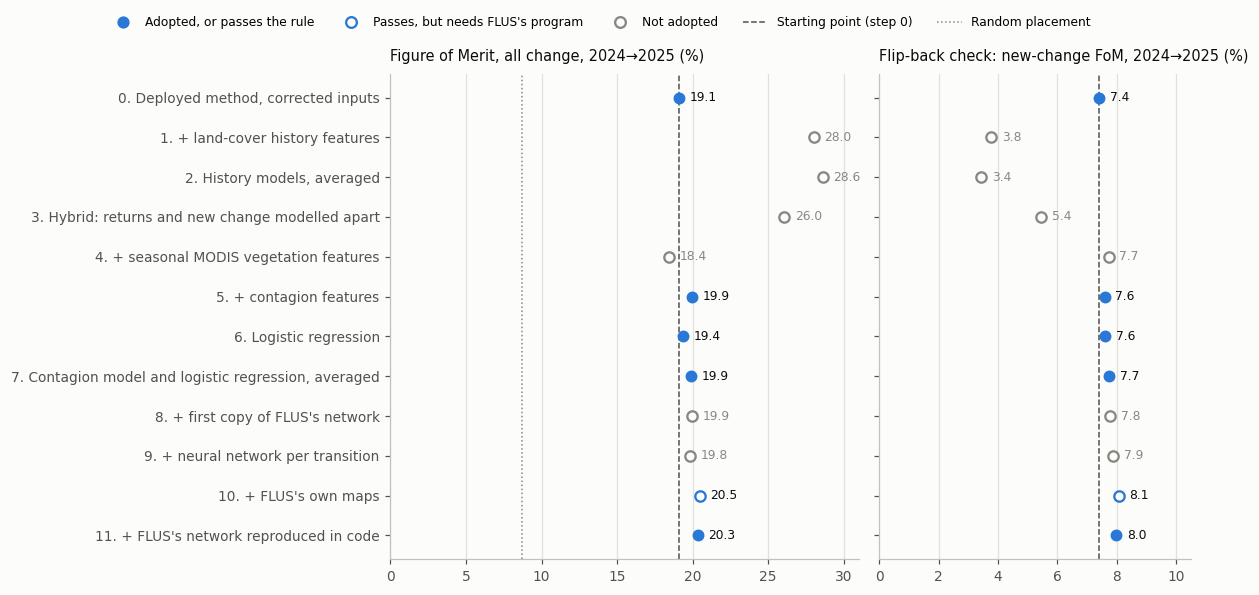

In [4]:
from matplotlib.lines import Line2D
fig, axes = plt.subplots(1, 2, figsize=(11, 5.4), sharey=True, gridspec_kw={"width_ratios": [3, 2]})
y = np.arange(len(steps))[::-1]
kind = np.select([steps["Decision"].str.startswith("passes, but"),
                  steps["Decision"].str.startswith(("starting", "adopted", "passes"))], ["outside", "kept"], "dropped")
STYLE = {"kept": dict(color=H.SERIES[0]), "outside": dict(facecolor=H.SURFACE, edgecolor=H.SERIES[0], lw=1.5),
         "dropped": dict(facecolor=H.SURFACE, edgecolor=H.MUTED, lw=1.5)}
for ax, col, title in ((axes[0], t, "Figure of Merit, all change, 2024→2025 (%)"),
                       (axes[1], ct, "Flip-back check: new-change FoM, 2024→2025 (%)")):
    H.style_axes(ax)
    ax.axvline(steps.loc[0, col], color=H.INK_2, lw=1, ls="--", zorder=1)
    for k, style in STYLE.items():
        ax.scatter(steps.loc[kind == k, col], y[kind == k], s=46, zorder=3, **style)
    for yi, x, k in zip(y, steps[col], kind):
        ax.annotate(f"{x:.1f}", (x, yi), xytext=(7, 0), textcoords="offset points", va="center", fontsize=8,
                    color=H.MUTED if k == "dropped" else H.INK)
    ax.set_title(title, loc="left", fontsize=9.5, color=H.INK, pad=8)
axes[0].axvline(floor, color=H.MUTED, lw=1, ls=":", zorder=1)
axes[0].set_yticks(y, [f"{s}. {i}" for s, i in zip(steps["Step"], steps["Idea"].str.replace(r" \(mean of 3.*\)| \(3 runs\)", "", regex=True))])
axes[0].set_ylim(y[-1] - 0.6, y[0] + 0.6)
axes[0].set_xlim(0, 31); axes[1].set_xlim(0, 10.5)
handles = [Line2D([], [], ls="", marker="o", ms=7, color=H.SERIES[0], label="Adopted, or passes the rule"),
           Line2D([], [], ls="", marker="o", ms=7, mfc=H.SURFACE, mec=H.SERIES[0], mew=1.5, label="Passes, but needs FLUS's program"),
           Line2D([], [], ls="", marker="o", ms=7, mfc=H.SURFACE, mec=H.MUTED, mew=1.5, label="Not adopted"),
           Line2D([], [], ls="--", color=H.INK_2, lw=1, label="Starting point (step 0)"),
           Line2D([], [], ls=":", color=H.MUTED, lw=1, label="Random placement")]
fig.legend(handles=handles, loc="upper center", ncol=5, frameon=False, fontsize=8, bbox_to_anchor=(0.5, 1.0))
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

**Reading:**

* **Left:** the history and hybrid steps (1–3) score highest on all change. **Right:** they are the
  only steps that fall well below the starting point on genuinely new change. Their gain is flicker,
  not land change.
* **The adopted steps move the score up a little at a time,** from 19.07% to 19.87% (steps 5–7) and
  20.33% (step 11), and they keep or raise the new-change score (7.39% → 7.75% → 7.97%).
* Gains of half a point are small, but each one is larger than the spread across seeds (±0.04 to
  ±0.09 points), was chosen on one year and held on the next.

## 4 · The method now

| | Deployed method (corrected inputs) | First improved method (steps 5–7) | Improved method now (step 11) |
|---|---|---|---|
| Suitability models | Random forest per transition | + contagion features, averaged with a logistic regression | + FLUS's network reproduced in code (`flus_ann.py`); the three averaged with equal weight |
| FoM 2023→2024 | 15.58% | 18.08% | 18.53% |
| FoM 2024→2025 | 19.07% | 19.87% | 20.33% |
| New data needed | – | None | None |
| Extra run time | – | Minutes | About 2 minutes a year |

Step 11 was adopted on 24 October 2026, and the tool comparison (notebooks 00 and 10) was rerun
with it: 20.4% as it runs (seed 42), ahead of every tool, and 13.1% with projected amounts.

**Still to do:**

1. **Confirm on 2025→2026** when Esri publishes its 2026 map: the only test year not used to
   choose anything. Steps 8–11 came from FLUS's 2024→2025 result, so for them 2024→2025 is a weaker
   test. Meanwhile the gain holds on an earlier year, 2022→2023 (section 5).
2. **Move the adopted steps to the platform** (`landuse_tool`). Settings are fixed, so the
   2025→2026 rerun confirms them rather than changing them.

## 5 · A second test year: 2022→2023

2025→2026 is the independent test, once Esri publishes its 2026 map. Meanwhile the three methods are
run on an earlier year: trained on 2021→2022, forecasting 2023. No setting was ever chosen on how
well 2023 was forecast (the 2023 map was only used as the end of a training interval), so this is a
second check of the gain, with three seeds each. It is not fully independent: the methods were
designed after looking at the later years.

In [5]:
import esri_methods as E, predictor_tests as P, benchmark_export as BX
BX.another_year(2022)                                   # FLUS's inputs for the 2022 start (only if missing)
g = H.guinea_mask(E.grid())
SEEDS = {"": 42, "_seed1": 1, "_seed2": 2}
for sfx, seed in SEEDS.items():
    if not E.load_result(f"R0c_guinea_dated{sfx}", "backtest"):
        E.run_deployed("backtest", "guinea", "dated", "start", tag=f"R0c_guinea_dated{sfx}", seed=seed)
    P.improved_variant(f"backtest_improved{sfx}", "backtest", seed=seed)          # step 11: all three parts
    if not E.load_result(f"backtest_first{sfx}", "backtest"):                       # step 7: without FLUS's network
        part = lambda p: E.atlas_from(E.RUNS / f"backtest_improved{sfx}_{p}" / "backtest" / "surfaces", "expander")
        E.run_average(f"backtest_first{sfx}", "backtest", part("rf"), part("lr"))
b22, c23 = E.esri_cached(2022), E.esri_cached(2023)
forecast = lambda tag: H.read_tif(E.RUNS / tag / "backtest" / "allocation" / "Expander-only" / "predicted_land_cover.tif")[0]
dep = forecast("R0c_guinea_dated")
floor22 = np.mean([E.change_kind_scores(2022, c23, E.random_like(b22, dep, g & E.valid_classes(b22, c23, dep), seed=s), g)["FoM"]
                   for s in range(3)])
METHODS = {"Deployed method, corrected inputs (step 0)": ("R0c_guinea_dated", 0),
           "First improved method (step 7)": ("backtest_first", 7), "Improved method now (step 11)": ("backtest_improved", 11)}
back = []
for name, (tag, n) in METHODS.items():
    sc = [E.change_kind_scores(2022, c23, forecast(tag + sfx), g) for sfx in SEEDS]
    fom = [x["FoM"] for x in sc]
    back.append({"Method (mean of 3 seeds)": name, "FoM % 2022→2023 (back-test)": np.mean(fom), "± across seeds": (max(fom) - min(fom)) / 2,
                 "Check: new-change FoM % 2022→2023": np.mean([x["new"]["FoM"] for x in sc]),
                 "× random 2022→2023": np.mean(fom) / floor22, v: steps.loc[n, v], t: steps.loc[n, t]})
back = pd.DataFrame(back)
back.to_csv(H.SUMMARY / "11_backtest.csv", index=False)
print(f"Random placement 2022→2023: {floor22:.2f}%")
H.show(back)

Written D:\Guinea_Methodology\landuse_experiments\outputs\benchmark\inputs\factors_2022_flus


[R0c_guinea_dated/backtest] 13 significant transitions; features 12


   2->4 done (7 s)


   2->5 done (14 s)


   2->7 done (20 s)


...

[2022, seed 2] trained on 80,214 pixels; RMSE 0.209


[backtest_improved_seed2/backtest] FoM 15.97


[backtest_first_seed2/backtest] FoM 15.88


Random placement 2022→2023: 5.25%


Method (mean of 3 seeds),FoM % 2022→2023 (back-test),± across seeds,Check: new-change FoM % 2022→2023,× random 2022→2023,FoM % 2023→2024,FoM % 2024→2025
"Deployed method, corrected inputs (step 0)",15.16,0.04,7.92,2.89,15.58,19.07
First improved method (step 7),15.88,0.03,8.18,3.03,18.08,19.87
Improved method now (step 11),15.94,0.03,8.27,3.04,18.53,20.33


**Reading:**

* **The gain holds on 2022→2023.** The first improved method scores 15.88% and the method now
  15.94%, against 15.16% for the deployed method: +0.8 points, well beyond the spread across seeds
  (±0.03–0.04), and 3.0 times random placement (5.25%).
* **Both pass the flip-back check:** new-change FoM 8.18% and 8.27%, against 7.92%.
* **The gain is smaller than on the later years** (+2.9 on 2023→2024, +1.3 on 2024→2025). Adding
  FLUS's network (step 7 to step 11) adds 0.06 points here, just above the seed spread: small, but
  in the same direction as on the other two years (+0.44 and +0.46).

### References

* Bouthillier, X., et al. (2021). Accounting for variance in machine learning benchmarks.
  *Proceedings of Machine Learning and Systems* 3.
* Liu, X., Liang, X., Li, X., et al. (2017). A future land use simulation model (FLUS) for simulating
  multiple land use scenarios by coupling human and natural effects. *Landscape and Urban Planning*
  168, 94–116.
* Pontius, R.G. Jr., Huffaker, D., Denman, K. (2004). Useful techniques of validation for
  spatially explicit land-change models. *Ecological Modelling* 179(4), 445–461.
* Pontius, R.G. Jr., Boersma, W., Castella, J.-C., et al. (2008). Comparing the input, output,
  and validation maps for several models of land change. *Annals of Regional Science* 42(1), 11–37.
* Rosa, I.M.D., Purves, D., Souza, C. Jr., Ewers, R.M. (2013). Predictive modelling of
  contagious deforestation in the Brazilian Amazon. *PLoS ONE* 8(10), e77231.